# Data Inventory
## Purpose: Inspect  all source datasets before cleaning, record structure, coverage and quality issues, and decide what is usable.

In [1]:
import pandas as pd
pd.set_option('display.max_columns', 50)

## 1. ONS London rental statistics (Apr 2025 – Mar 2026)

**Source:** Office for National Statistics
**Coverage:** April 2025 – March 2026
**Licence:** Open Government Licence v3.0

In [2]:
rents = pd.read_excel('../data/raw/londonrentalstatsaccessibleq12026.xlsx', sheet_name='3', header=2).dropna(how='all')
print(rents.shape)
rents.head()

(1974, 7)


,Postcode District,Bedroom Category,Count of rents,Mean,Lower quartile,Median,Upper quartile
0,BR1,Room,20,756,703,773,848
1,BR1,Studio,20,1058,1026,1075,1119
2,BR1,One Bedroom,170,1369,1300,1400,1450
3,BR1,Two Bedrooms,230,1657,1500,1650,1800
4,BR1,Three Bedrooms,100,2011,1800,2000,2213


In [3]:
for col in ['Count of rents','Mean','Lower quartile','Median','Upper quartile']: rents[col] = pd.to_numeric(rents[col], errors='coerce')

print("Districts:", rents['Postcode District'].nunique())
print("Suppressed medians:", rents['Median'].isna().sum())
rents['Median'].describe()

Districts: 329
Suppressed medians: 927


count    1047.000000
mean     2111.755492
std      1017.355092
min       521.000000
25%      1450.000000
50%      1900.000000
75%      2550.000000
max      9975.000000
Name: Median, dtype: float64

## Findings
1. 1,974 rows, 329 postcode districts, six bedroom categories
2. 927 medians suppressed (47%) — only 1,047 usable rows
3. Suppression is not random: Room 76%, Studio 66%, Four+ bed 48%, Three bed 34%, One bed 30%, Two bed 29%
4. Only 48 of 329 districts have all six categories; 247 have at least one
5. Suppressed values coded ..
6. Median two-bed London rent: £1,900

## 2. ONS PIPR

**Source**: Office for National Statistics
**Coverage**: January 2015 – August 2026, monthly
**Licence**: Open Government Licence v3.0

In [4]:
pipr = pd.read_excel('../data/raw/priceindexofprivaterentsukmonthlypricestatistics.xlsx', sheet_name='Table 1', header=2).dropna(how='all')
print(pipr.shape)
pipr.head()

(49980, 40)


,Time period,Area code,Area name,Region or country name,Index,Monthly change,Annual change,Rental price,Index one bed,Monthly change one bed,Annual change one bed,Rental price one bed,Index two bed,Monthly change two bed,Annual change two bed,Rental price two bed,Index three bed,Monthly change three bed,Annual change three bed,Rental price three bed,Index four or more bed,Monthly change four or more bed,Annual change four or more bed,Rental price four or more bed,Index detached,Monthly change detached,Annual change detached,Rental price detached,Index semidetached,Monthly change semidetached,Annual change semidetached,Rental price semidetached,Index terraced,Monthly change terraced,Annual change terraced,Rental price terraced,Index flat maisonette,Monthly change flat maisonette,Annual change flat maisonette,Rental price flat maisonette
0,2015-01-01,K02000001,United Kingdom,[z],81.258259,[x],[x],910,82.339979,[x],[x],736,82.240944,[x],[x],840,80.084844,[x],[x],916,79.857966,[x],[x],1371,78.184174,[x],[x],1020,80.313297,[x],[x],897,80.345118,[x],[x],893,83.26757,[x],[x],904
1,2015-02-01,K02000001,United Kingdom,[z],81.413747,0.191351,[x],912,82.53953,0.24235,[x],738,82.417101,0.214196,[x],842,80.270495,0.231817,[x],918,79.939432,0.102014,[x],1372,78.352679,0.215523,[x],1022,80.44485,0.1638,[x],899,80.478716,0.166281,[x],894,83.457123,0.227644,[x],906
2,2015-03-01,K02000001,United Kingdom,[z],81.663685,0.306997,[x],915,82.781781,0.293496,[x],740,82.67116,0.30826,[x],844,80.458389,0.234076,[x],920,80.299179,0.450024,[x],1378,78.5985,0.313736,[x],1025,80.649125,0.253931,[x],901,80.72993,0.312149,[x],897,83.73479,0.332706,[x],909
3,2015-04-01,K02000001,United Kingdom,[z],81.990506,0.400204,[x],918,83.232795,0.544823,[x],744,82.989438,0.384992,[x],847,80.756962,0.37109,[x],923,80.53818,0.297639,[x],1382,78.819084,0.280648,[x],1028,80.939574,0.36014,[x],904,80.995081,0.328442,[x],900,84.194112,0.548543,[x],914
4,2015-05-01,K02000001,United Kingdom,[z],82.343646,0.430708,[x],922,83.597644,0.438349,[x],748,83.362729,0.449806,[x],851,81.062889,0.378825,[x],927,80.793511,0.317031,[x],1387,79.060374,0.306131,[x],1031,81.235557,0.365684,[x],908,81.33684,0.421951,[x],904,84.638073,0.527307,[x],918


In [5]:
print("Areas:", pipr['Area name'].nunique())
print("Date range:", pipr['Time period'].min(), "to", pipr['Time period'].max())
print("\nSample areas:", list(pipr['Area name'].unique()))

Areas: 357
Date range: 2015-01-01 00:00:00 to 2026-08-01 00:00:00

Sample areas: ['United Kingdom', 'Great Britain', 'England', 'Wales', 'Scotland', 'Northern Ireland', 'North East', 'North West', 'Yorkshire and The Humber', 'East Midlands', 'West Midlands', 'East of England', 'London', 'South East', 'South West', 'Hartlepool', 'Middlesbrough', 'Redcar and Cleveland', 'Stockton-on-Tees', 'Darlington', 'Halton', 'Warrington', 'Blackburn with Darwen', 'Blackpool', 'Kingston upon Hull, City of', 'East Riding of Yorkshire', 'North East Lincolnshire', 'North Lincolnshire', 'York', 'Derby', 'Leicester', 'Rutland', 'Nottingham', 'Herefordshire, County of', 'Telford and Wrekin', 'Stoke-on-Trent', 'Bath and North East Somerset', 'Bristol, City of', 'North Somerset', 'South Gloucestershire', 'Plymouth', 'Torbay', 'Swindon', 'Peterborough', 'Luton', 'Southend-on-Sea', 'Thurrock', 'Medway', 'Bracknell Forest', 'West Berkshire', 'Reading', 'Slough', 'Windsor and Maidenhead', 'Wokingham', 'Milton Ke

In [6]:
london = pipr[pipr['Area name'] == 'London'].copy()
london['Time period'] = pd.to_datetime(london['Time period'])

cols = ['Time period','Index','Rental price',
        'Rental price one bed','Rental price two bed',
        'Rental price three bed','Rental price four or more bed']
london[cols]

,Time period,Index,Rental price,Rental price one bed,Rental price two bed,Rental price three bed,Rental price four or more bed
1680,2015-01-01,86.294082,1580,1170,1520,1775,2527
1681,2015-02-01,86.488668,1583,1173,1524,1781,2530
1682,2015-03-01,86.873807,1590,1178,1531,1788,2545
1683,2015-04-01,87.546011,1602,1187,1543,1803,2563
1684,2015-05-01,88.278336,1616,1196,1557,1819,2582
...,...,...,...,...,...,...,...
1815,2026-04-01,125.131683,2290,1730,2192,2590,3582
1816,2026-05-01,125.346781,2294,1733,2196,2596,3586
1817,2026-06-01,125.789028,2302,1740,2205,2607,3594
1818,2026-07-01,126.581542,2317,1752,2218,2623,3614


In [7]:
codes = pipr.astype(str).apply(lambda c: c.str.strip().isin(['[x]','[z]','[c]','..']).sum())
print(codes[codes > 0].sort_values(ascending=False))

Annual change                      4302
Annual change terraced             4302
Annual change three bed            4302
Annual change four or more bed     4302
Annual change two bed              4302
Annual change one bed              4302
Annual change semidetached         4302
Annual change flat maisonette      4302
Annual change detached             4302
Region or country name             2100
Area code                          1120
Monthly change detached             375
Monthly change                      375
Monthly change semidetached         375
Monthly change three bed            375
Monthly change four or more bed     375
Monthly change flat maisonette      375
Monthly change terraced             375
Monthly change two bed              375
Monthly change one bed              375
Rental price                         18
Index                                18
Rental price four or more bed        18
Index four or more bed               18
Index three bed                      18


In [8]:
# [x] = not available, [z] = not applicable
print("Index column before conversion:")
print(pipr['Index'].astype(str).str.strip()
      .loc[lambda s: s.isin(['[x]','[z]'])].value_counts())

pipr['Index'] = pd.to_numeric(pipr['Index'], errors='coerce')
print("\nNumeric values:", pipr['Index'].notna().sum(), "of", len(pipr))

Index column before conversion:
Index
[x]    18
Name: count, dtype: int64

Numeric values: 49962 of 49980


In [9]:
london_idx = london[['Time period','Index']].dropna()
base = london_idx[london_idx['Time period'] == '2024-05-01']['Index'].values[0]
latest = london_idx['Index'].dropna().iloc[-1]
print(f"May 2024 index: {base:.2f}")
print(f"Latest index:   {latest:.2f}")
print(f"Adjustment factor: {latest/base:.4f}")

May 2024 index: 114.05
Latest index:   127.40
Adjustment factor: 1.1170


In [10]:
london_idx

,Time period,Index
1680,2015-01-01,86.294082
1681,2015-02-01,86.488668
1682,2015-03-01,86.873807
1683,2015-04-01,87.546011
1684,2015-05-01,88.278336
...,...,...
1815,2026-04-01,125.131683
1816,2026-05-01,125.346781
1817,2026-06-01,125.789028
1818,2026-07-01,126.581542


## Findings

1. 49,980 rows = 357 areas × 140 months (Jan 2015 – Aug 2026)
2. Rental price and index by bedroom count and property type
3. Missing values coded [x] (not available) and [z] (not applicable)
4. All missingness is structural, not quality-related:
   2,100 — 15 top-level areas have no parent region
   1,120 — 8 NI BRMAs have no ONS area code
   4,302 — no annual change in the first 12 months of each series
   375 — no monthly change in January 2015
   18 — Northern Ireland publishes two months late
5. Areas mix UK, countries, regions, local authorities and BRMAs with no level indicator
6. London coverage is complete, all 140 months
7. **Adjustment factor May 2024 → Aug 2026: 1.1170 (+11.7%)**


## 3. VOA Average Private Rents by Borough (archive)

**Source**: Valuation Office Agency, via London Datastore (GLA)
**Coverage**: 2011 Q2 – 2019, 33 London boroughs
**Licence**: Open Government Licence v2.0

In [11]:
voa = pd.read_excel('../data/raw/voa-average-rent-borough.xls', sheet_name='Raw data', header=2)
voa = voa.dropna(how='all')
print(voa.shape)
print(list(voa.columns))
voa.head()

(6160, 10)
['Year', 'Quarter', 'Code', 'Area', 'Category', 'Count of rents', 'Average', 'Lower quartile', 'Median', 'Upper quartile']


,Year,Quarter,Code,Area,Category,Count of rents,Average,Lower quartile,Median,Upper quartile
0,2011,Q2,E09000001,City of London,Room,-,-,-,-,-
1,2011,Q2,E09000002,Barking and Dagenham,Room,92,336,282,347,390
2,2011,Q2,E09000003,Barnet,Room,945,450,399,433,500
3,2011,Q2,E09000004,Bexley,Room,119,390,347,390,433
4,2011,Q2,E09000005,Brent,Room,344,469,390,457,550


In [12]:
print("Rows:", voa.shape)
print("Years:", sorted(voa['Year'].dropna().unique()))
print("Areas:", voa['Area'].nunique())
print("Categories:", list(voa['Category'].dropna().unique()))

Rows: (6160, 10)
Years: [np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019)]
Areas: 44
Categories: ['Room', 'Studio', 'One Bedroom', 'Two Bedroom', 'Three Bedroom', 'Four or more Bedrooms', 'All categories']


Boroughs: 33


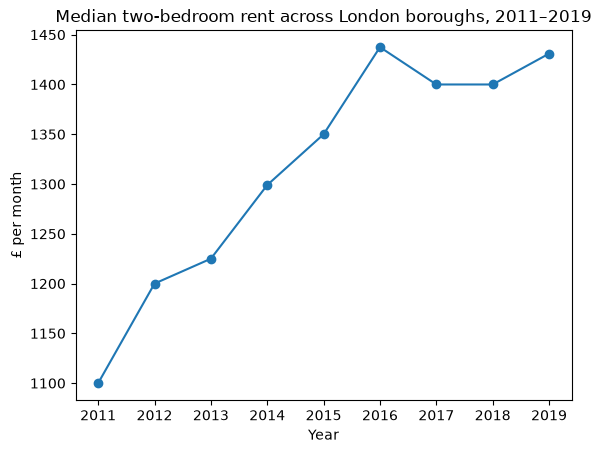

In [13]:
import matplotlib.pyplot as plt

regions = ['EAST','EAST MIDLANDS','LONDON','NORTH EAST','NORTH WEST',
           'SOUTH EAST','SOUTH WEST','WEST MIDLANDS','YORKSHIRE AND THE HUMBER',
           'Inner London','Outer London']

two_bed = voa[(voa['Category'] == 'Two Bedroom') &
              (~voa['Area'].isin(regions))].copy()
two_bed['Median'] = pd.to_numeric(two_bed['Median'], errors='coerce')

print("Boroughs:", two_bed['Area'].nunique())   # should be 33

trend = two_bed.groupby('Year')['Median'].median()
trend.plot(marker='o', title='Median two-bedroom rent across London boroughs, 2011–2019')
plt.ylabel('£ per month')
plt.show()

## Findings
1. 6,160 rows, 2011 Q2 – 2019
2. Area column mixes 33 boroughs with 8 English regions and 3 London aggregates (LONDON, Inner London, Outer London)
3. Category includes an All categories aggregate alongside the six real categories
4. Missing values coded - (43 in Median)
5. Filtering mattered: unfiltered gave £1,344 for 2019, boroughs-only gives £1,431
6. Median two-bed rose £1,100 (2011) → £1,431 (2019), plateauing from 2017
7. Against Section 1's £1,900, roughly a third higher in six years
8. Archive only — not used for modelling


## 4. Rightmove rental listings (Kaggle)

**Source**: Kaggle, psgpyc/london-property-rental
**Content**: 3,478 London rental advertisements scraped from Rightmove, c. 2024
**Licence**: see dataset page



In [14]:
ads = pd.read_csv('../data/raw/rent_ads_rightmove_extended.csv')
print(ads.shape)

pd.DataFrame({
    'non_null': ads.notna().sum(),
    'pct': (ads.notna().sum()/len(ads)*100).round(1),
    'unique': ads.nunique()
})

(3478, 13)


,non_null,pct,unique
address,3478,100.0,2879
subdistrict_code,1868,53.7,211
rent,3478,100.0,695
deposit,3478,100.0,612
Let type,3235,93.0,2
Furnish Type,3477,100.0,5
Coucil Tax,3477,100.0,3
PROPERTY TYPE,3438,98.8,27
BEDROOMS,2841,81.7,7
BATHROOMS,3049,87.7,8


In [15]:
print(ads['Coucil Tax'].value_counts(), "\n")
print("SIZE = 'Ask agent':", (ads['SIZE']=='Ask agent').sum(), "of", len(ads), "\n")
print(ads['nearest_station_count'].value_counts())

Coucil Tax
Ask agent    3446
Exempt         17
Included       14
Name: count, dtype: int64 

SIZE = 'Ask agent': 2556 of 3478 

nearest_station_count
3    3469
2       9
Name: count, dtype: int64


In [16]:
ext = ads['address'].str.extract(r',\s*([A-Z]{1,2}[0-9][A-Z0-9]?)\s*$')[0]
ads['district'] = ads['subdistrict_code'].fillna(ext)
print("District coverage:", round(ads['district'].notna().mean()*100, 1), "%")

ads = ads[~ads['PROPERTY TYPE'].isin(['Parking','Garages'])]
ads.loc[(ads['PROPERTY TYPE']=='Studio') & ads['BEDROOMS'].isna(), 'BEDROOMS'] = 0
ads.loc[ads['PROPERTY TYPE'].isin(['House Share','Flat Share']) & ads['BEDROOMS'].isna(), 'BEDROOMS'] = 1

usable = ads.dropna(subset=['district','BEDROOMS','rent'])
print("Usable:", len(usable), "rows |", usable['district'].nunique(), "districts")
usable['rent'].describe()

District coverage: 67.2 %
Usable: 2167 rows | 227 districts


count     2167.000000
mean      2702.159206
std       2439.108471
min        449.000000
25%       1650.000000
50%       2375.000000
75%       3250.000000
max      52000.000000
Name: rent, dtype: float64

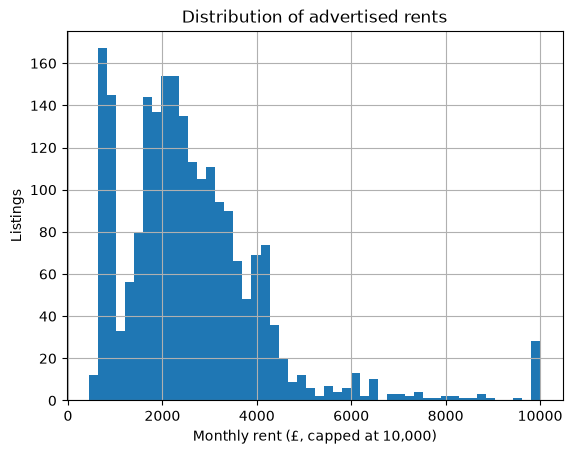

Above £10,000: 24 | max: 52000


In [17]:
usable['rent'].clip(upper=10000).hist(bins=50)
plt.xlabel('Monthly rent (£, capped at 10,000)')
plt.ylabel('Listings')
plt.title('Distribution of advertised rents')
plt.show()

print("Above £10,000:", (usable['rent']>10000).sum(), "| max:", usable['rent'].max())

## Findings
1. 3,478 rows, 13 columns
2. Council Tax 99.1% "Ask agent" → dropped
3. SIZE 73.5% "Ask agent" (2,556 of 3,478) → dropped
4. nearest_station_count: 3,469 of 3,478 are 3 → no variance, dropped
5. District recovered from address regex: 53.7% → 67.2%
6. Non-dwellings removed (Parking 83, Garages 36)
7. Bedrooms imputed: 0 for studios, 1 for shares
8. 2,167 usable rows, 227 districts
9. Rent heavily right-skewed: median £2,375, mean £2,702, max £52,000
10. Two distinct markets: room lettings (290 rows, median £802) vs whole properties (1,877 rows, median £2,600)
11. Top rents in NW8, W8, SW7 are genuine, not errors

# 5. Summary
| Dataset	| Rows usable |	Role | Key limitation |
|---|---|---|---|
| ONS London Q1 2026	| 1,047 of 1,974 |	Benchmark	| 47% suppressed; worst for rooms (76%) and studios (66%) |
| ONS PIPR	| 49,962 |	Time adjustment, property type |	Mixed geographic levels; structural missingness only |
| VOA archive |	6,160	| Historical context |	Ends 2019; not used for modelling |
| Rightmove listings |	2,167 of 3,478 |	Model training |	c.2024; council tax and size unusable; two distinct markets |

### Cross-cutting observations

Two patterns recur across all four sources.

Every dataset encodes missing values differently: `..` in the ONS postcode
data, `[x]` and `[z]` in PIPR, `-` in the VOA archive, and the string
`"Ask agent"` in the Rightmove listings. None use standard nulls, so
`isna()` alone would have detected none of it.

All three official datasets interleave geographic hierarchy levels within
a single column, with no field indicating which level a row belongs to.
PIPR mixes UK, country, region, local authority and BRMA rows; the VOA
file mixes boroughs with English regions and London aggregates. Any
aggregation without explicit filtering double-counts, as shown in Section 3
where unfiltered figures understated 2019 median rent by £87.